---

# HoloMine Property Price Prediction

*Prediksi `listPrice` dari teks listing properti, dilatih end-to-end pada satu RTX 5090.*

---

## HOLOGY 9.0 - HoloMine Task 2

- Target runtime: Vast.ai, satu NVIDIA RTX 5090 (32 GB, Blackwell sm_120)
- Sumber data: hanya `data/train.csv`, `data/test.csv`, dan bobot pretrained publik
- Metrik: Mean Absolute Error pada skala dolar

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Contract and Preprocessing**](#3)
4. [**Validation Design**](#4)
5. [**Sparse and Tree Baselines**](#5)
6. [**Transformer Fine-Tuning**](#6)
7. [**Blending and Calibration**](#7)
8. [**Submission**](#8)

---

# Introduction <a name="1"></a>

---

## Overview

*Kompetisi menyediakan satu kolom teks per listing dan meminta harga jualnya. Seluruh atribut terstruktur, seperti luas bangunan, jumlah kamar, tahun bangun, dan alamat, sudah dihapus dari tabel dan hanya tersisa sebagai kalimat di dalam deskripsi. Tugasnya adalah mengembalikan informasi itu menjadi angka.*

Notebook ini adalah iterasi kedua. Iterasi pertama melatih ModernBERT langsung pada harga dolar dengan Huber loss dan berhenti di MAE 632 ribu, lebih buruk daripada ridge TF-IDF sederhana. Audit EDA di `src/eda/` menunjukkan penyebabnya bukan arsitektur melainkan ruang target, dan seluruh keputusan di bawah ini mengikuti temuan tersebut.

## Aim

- Memprediksi `listPrice` untuk 3.659 baris `test.csv`.
- Menurunkan MAE dengan memperbaiki ruang target dan loss sebelum menyentuh arsitektur.
- Menjaga cross-validation tetap jujur terhadap duplikat teks dan tetap stabil terhadap ekor harga.

## Metric

Submisi dinilai dengan Mean Absolute Error pada skala dolar.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|$$

MAE diminimalkan oleh median bersyarat, bukan rata-rata bersyarat. Karena `exp` monoton, median harga sama dengan eksponensial dari median log harga. Konsekuensinya sangat konkret: model diregresikan pada log harga dengan loss bertipe L1, lalu hasilnya dieksponensialkan.

## Dataset

| File | Baris | Kolom |
| --- | --- | --- |
| `train.csv` | 14.640 | `id`, `text`, `listPrice` |
| `test.csv` | 3.659 | `id`, `text` |
| `sample_submission.csv` | 3.659 | `id`, `listPrice` |

Harga membentang dari 1 dolar sampai 80 juta dolar dengan median 499.900 dan skewness 15,3. Dalam ruang log, skewness turun menjadi -0,22, praktis simetris.

## Approach

Lima keputusan berikut berasal langsung dari EDA dan dipakai di seluruh notebook.

1. **Target log, loss L1.** Pindah dari ruang dolar ke ruang log menurunkan MAE ridge dari 514.990 menjadi 356.188 pada fold yang sama, yaitu 30,8 persen, lebih besar daripada efek pergantian arsitektur manapun yang tersedia.
2. **Perbaikan teks sebelum tokenisasi.** Scraper memecah pemisah ribuan menjadi `"12, 400"`, sehingga 2.557 kaki persegi terbaca sebagai 557. Perbaikan ini mengubah nilai `sqft` pada 345 baris.
3. **Fold berbasis grup dan terstratifikasi harga.** Duplikat teks dikelompokkan agar tidak bocor antar fold, dan setiap fold mendapat porsi ekor harga yang setara agar delta CV bermakna.
4. **Kalibrasi setelah prediksi.** Model menyusut ke tengah; desil teratas diprediksi hanya 0,84 kali harga sebenarnya. Isotonic regression yang dipasang out-of-fold mengembalikan sebagian.
5. **Ensemble tiga keluarga model.** Sparse TF-IDF, gradient boosting atas fitur hasil ekstraksi, dan transformer, digabung dengan bobot yang dicari pada OOF.

#### Insights

> Tiga puluh empat persen dari seluruh MAE berasal dari 220 baris di atas 5 juta dolar, dan 58 persen berasal dari 9 persen baris di atas 1,5 juta dolar. Perbaikan pada rumah mewah bernilai jauh lebih besar daripada perbaikan pada rumah median.

> Pasangan listing yang teksnya nyaris identik masih berbeda harga rata-rata 122.705 dolar. Angka itu adalah lantai kesalahan yang tidak bisa ditembus model berbasis teks saja.

---

# Initialization <a name="2"></a>

---

## Environment Setup

RTX 5090 memakai arsitektur Blackwell dengan compute capability 12.0, sehingga wheel PyTorch harus dibangun untuk CUDA 12.8 atau lebih baru. Sel berikut memeriksa apakah torch bawaan image sudah mendukung `sm_120` dan hanya mengunduh ulang kalau belum, lalu memasang sisa dependensi. Sel setelahnya mencetak kapabilitas GPU supaya kesalahan versi terlihat sebelum training dimulai, bukan sesudahnya.

In [1]:
%pip install -q --upgrade pip
!python -c "import sys, torch; sys.exit(0 if 'sm_120' in torch.cuda.get_arch_list() else 1)" || pip install -q torch --index-url https://download.pytorch.org/whl/cu128
%pip install -q 'transformers>=4.46' tokenizers sentencepiece tiktoken protobuf accelerate
%pip install -q scikit-learn lightgbm pandas pyarrow matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.
/bin/bash: line 1: python: command not found
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Libraries

Seluruh import dikumpulkan di satu sel agar dependensi setiap bagian notebook terlihat sekaligus.

In [2]:
import gc
import json
import math
import os
import random
import re
import time
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.sparse import csr_matrix, hstack
from scipy.optimize import nnls
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import LinearSVR
from scipy.sparse.csgraph import connected_components
from scipy.sparse import coo_matrix
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)

In [3]:
print('torch     :', torch.__version__)
print('cuda      :', torch.version.cuda)
print('device    :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    major, minor = torch.cuda.get_device_capability(0)
    total = torch.cuda.get_device_properties(0).total_memory / 1024 ** 3
    print(f'capability: sm_{major}{minor}')
    print(f'vram      : {total:.1f} GiB')
    print('bf16 ok   :', torch.cuda.is_bf16_supported())
    assert major >= 8, 'notebook ini mengasumsikan bf16, butuh Ampere atau lebih baru'

torch     : 2.11.0+cu128
cuda      : 12.8
device    : NVIDIA GeForce RTX 5090
capability: sm_120
vram      : 31.4 GiB
bf16 ok   : True


## Seed

Satu fungsi seed dipakai sebelum setiap fold supaya urutan sampling, inisialisasi head, dan dropout dapat diulang.

In [4]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything(42)

## Settings

Konfigurasi dikumpulkan dalam satu dataclass. `PROFILE` mengatur trade-off antara waktu dan skor: `smoke` untuk memastikan seluruh sel jalan dalam beberapa menit, `full` untuk run final. Nilai `max_length` 640 dipilih dari EDA, karena persentil 99 panjang teks test setara sekitar 790 token dan jendela 512 memotong justru listing mewah yang menyumbang mayoritas MAE.

In [5]:
PROFILE = 'full'


@dataclass
class Config:
    data_dir: Path = Path('data')
    out_dir: Path = Path('outputs/v2')
    seed: int = 42
    n_folds: int = 5
    price_floor: float = 10_000.0
    duplicate_threshold: float = 0.85
    twin_threshold: float = 0.97
    backbones: tuple = (
        ('microsoft/deberta-v3-large', 640, 8, 2, 1.0e-5),
        ('answerdotai/ModernBERT-large', 768, 8, 2, 1.5e-5),
    )
    epochs: float = 3.0
    head_lr: float = 1.0e-4
    llrd: float = 0.9
    weight_decay: float = 0.01
    warmup_ratio: float = 0.06
    huber_beta: float = 0.25
    evals_per_epoch: int = 2
    max_grad_norm: float = 1.0
    gradient_checkpointing: bool = False
    infer_batch_size: int = 32


CFG = Config()
if PROFILE == 'smoke':
    CFG.n_folds = 2
    CFG.epochs = 0.25
    CFG.backbones = (('microsoft/deberta-v3-base', 384, 16, 1, 2.0e-5),)

for candidate in (Path('data'), Path('../data'), Path('/workspace/data')):
    if (candidate / 'train.csv').exists():
        CFG.data_dir = candidate
        CFG.out_dir = candidate.parent / 'outputs' / 'v2'
        break
else:
    raise FileNotFoundError('data/train.csv tidak ditemukan, salin folder data ke sebelah notebook')

CFG.out_dir.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(json.dumps({k: str(v) for k, v in asdict(CFG).items()}, indent=2))

{
  "data_dir": "data",
  "out_dir": "outputs/v2",
  "seed": "42",
  "n_folds": "5",
  "price_floor": "10000.0",
  "duplicate_threshold": "0.85",
  "twin_threshold": "0.97",
  "backbones": "(('microsoft/deberta-v3-large', 640, 8, 2, 1e-05), ('answerdotai/ModernBERT-large', 768, 8, 2, 1.5e-05))",
  "epochs": "3.0",
  "head_lr": "0.0001",
  "llrd": "0.9",
  "weight_decay": "0.01",
  "warmup_ratio": "0.06",
  "huber_beta": "0.25",
  "evals_per_epoch": "2",
  "max_grad_norm": "1.0",
  "gradient_checkpointing": "False",
  "infer_batch_size": "32"
}


## Load Dataset

File kompetisi dibaca apa adanya, lalu dicek jumlah baris dan kolomnya terhadap deskripsi resmi sebelum diproses lebih lanjut.

In [6]:
train = pd.read_csv(CFG.data_dir / 'train.csv')
test = pd.read_csv(CFG.data_dir / 'test.csv')
sample_submission = pd.read_csv(CFG.data_dir / 'sample_submission.csv')

train['text'] = train['text'].fillna('')
test['text'] = test['text'].fillna('')

print('train', train.shape)
print('test ', test.shape)
print('sub  ', sample_submission.shape)
assert list(train.columns) == ['id', 'text', 'listPrice']
assert list(test.columns) == ['id', 'text']
assert test['id'].tolist() == sample_submission['id'].tolist()
train.head(3)

train (14640, 3)
test  (3659, 2)
sub   (3659, 2)


,id,text,listPrice
0,RE_009688,"Nestled in the heart of Randolph, [Redacted En...",185000.0
1,RE_015920,Beautiful end-unit townhouse in desirable Quin...,175000.0
2,RE_014937,Lovely 1925 bungalow! Forced air. Unfinished b...,339500.0


In [7]:
y_price = train['listPrice'].to_numpy(dtype=float)
log_price = np.log(np.clip(y_price, CFG.price_floor, None))

print(f'median      {np.median(y_price):>14,.0f}')
print(f'mean        {y_price.mean():>14,.0f}')
print(f'max         {y_price.max():>14,.0f}')
print(f'skew raw    {pd.Series(y_price).skew():>14.2f}')
print(f'skew log    {pd.Series(log_price).skew():>14.2f}')
print(f'MAE median-constant baseline: {np.abs(y_price - np.median(y_price)).mean():,.0f}')

median             499,900
mean               839,073
max             80,000,000
skew raw             15.29
skew log             -0.22
MAE median-constant baseline: 550,252


#### Insights

> Skewness turun dari 15,29 menjadi -0,22 hanya dengan logaritma. Distribusi log praktis simetris, yang berarti satu unit gradien di ruang log memberi bobot setara pada rumah 200 ribu dan rumah 20 juta. Di ruang dolar, 1,5 persen baris termahal akan menguasai hampir seluruh gradien.

> Baseline konstan median memberi MAE 550.252. Angka ini adalah garis yang harus dilewati model apapun sebelum dianggap belajar sesuatu.

---

# Data Contract and Preprocessing <a name="3"></a>

---

Bagian ini memindahkan hasil audit `src/eda/02_text_quality_audit.py` dan `src/prep/01_build_dataset.py` ke dalam notebook sehingga run di Vast.ai tidak bergantung pada artefak lokal. Dua kerusakan sistematis diperbaiki lebih dulu, kemudian fakta numerik ditarik kembali dari prosa.

## Text Repair

Pemisah ribuan berubah menjadi koma diikuti spasi pada 4,4 persen baris train dan 5,4 persen baris test, sehingga `"2, 557 square feet"` terbaca sebagai angka 2 lalu angka 557. Tanda baca juga kehilangan spasi setelahnya pada 11 persen baris, menghasilkan token gabungan seperti `convenience.Step` dan `views,this` yang tidak ada di vocabulary manapun. Aturan titik hanya berlaku sebelum huruf kapital agar desimal dan singkatan seperti `U.S.A.` selamat, dan lookbehind pada huruf kecil menjaga pemisah ribuan `1,850` tetap utuh.

In [8]:
SPLIT_NUMBER = re.compile(r'(?<=\d),\s+(?=\d{3}\b)')
GLUED_SENTENCE = re.compile(r'(?<=[a-z0-9])\.(?=[A-Z])')
GLUED_PUNCT = re.compile(r'(?<=[a-z])([,;:!?])(?=[A-Za-z])')
MULTISPACE = re.compile(r'\s+')
REDACTION = re.compile(r'\[Redacted Entity\]')
UNGLUE_LOWER_UPPER = re.compile(r'(?<=[a-z]{3})(?=[A-Z][a-z]{2})')


def repair_text(text: str) -> str:
    text = SPLIT_NUMBER.sub('', text)
    text = GLUED_SENTENCE.sub('. ', text)
    text = GLUED_PUNCT.sub(r'\1 ', text)
    return MULTISPACE.sub(' ', text).strip()


def model_text(text: str) -> str:
    text = repair_text(text)
    text = REDACTION.sub('[ADDRESS]', text)
    return UNGLUE_LOWER_UPPER.sub(' ', text)


for frame in (train, test):
    frame['clean'] = frame['text'].map(repair_text)
    frame['model_text'] = frame['text'].map(model_text)

affected = train['text'].str.contains(r'(?<=\d),\s+\d{3}\b', regex=True)
print(f'baris dengan pemisah ribuan rusak : {affected.sum():,} ({affected.mean():.2%})')
example = train.loc[affected, 'text'].iloc[0]
window = re.search(r'.{0,50}\d,\s+\d{3}.{0,50}', example).group(0)
print('\nsebelum :', window)
print('sesudah :', repair_text(window))

baris dengan pemisah ribuan rusak : 646 (4.41%)

sebelum :  on a sunny 0.17-acre corner lot in Astoria, this 2, 557-square-foot residence offers 4 bedrooms and 4 bat
sesudah : on a sunny 0.17-acre corner lot in Astoria, this 2557-square-foot residence offers 4 bedrooms and 4 bat


## Fact Extraction

Kolom terstruktur yang dihapus panitia masih tertulis sebagai kalimat. Regex berikut menarik kembali luas, lahan, kamar, kamar mandi, garasi, lantai, unit, dan tahun. Nilai di luar rentang fisik yang masuk akal dibuang, bukan dipotong, karena hasil parsing yang salah adalah derau dan bukan rumah kecil.

In [9]:
NUM = r'(\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)?)'
MOD = (r'(?:\+/-|\+\-)?[\s-]*'
       r'(?:(?:deeded|irrigated|usable|buildable|wooded|level|flat|total|gross|open|pasture|'
       r'tillable|more|or|less|approx\.?|approximately|additional|private|beautiful|rolling)[\s-]+){0,3}')

FACT_PATTERNS = {
    'sqft': rf'{NUM}[\s-]*{MOD}(?:square[-\s]?(?:feet|foot|ft)|sq\.?\s?ft\.?|sf\b|ft2\b)',
    'acres': rf'{NUM}[\s-]*{MOD}(?:acres?\b|ac\.?\s)',
    'beds': rf'{NUM}[\s-]*(?:bed\b|beds\b|bedroom|br\b|bdrm|bd\b)',
    'baths': rf'{NUM}[\s-]*(?:bath|ba\b|full bath)',
    'car_garage': rf'{NUM}[\s-]*car\b',
    'stories': rf'{NUM}[\s-]*(?:story|stories)\b',
    'units': rf'{NUM}[\s-]*unit',
}
SANE_RANGE = {
    'sqft': (120.0, 200_000.0), 'acres': (0.005, 200_000.0), 'beds': (1.0, 40.0),
    'baths': (0.5, 40.0), 'car_garage': (1.0, 12.0), 'stories': (1.0, 6.0), 'units': (1.0, 500.0),
}
YEAR_PATTERN = re.compile(r'\b(1[89]\d{2}|20[0-2]\d)\b')
BUILT_YEAR = re.compile(
    r'(?:built|constructed|erected|established|circa|c\.)\s*(?:in\s*)?(1[89]\d{2}|20[0-2]\d)'
    r'|(1[89]\d{2}|20[0-2]\d)[\s-]*(?:built|construction|vintage|colonial|bungalow|farmhouse|victorian)',
    re.I,
)
WORD_NUMBERS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
                'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10}
WORD_BED = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+bed', re.I)
WORD_HALF_BATH = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+and[\s-]+a[\s-]+half[\s-]+bath', re.I)
WORD_BATH = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+bath', re.I)


def to_float(token: str) -> float:
    try:
        return float(token.replace(',', ''))
    except ValueError:
        return np.nan


def extract_facts(text: str) -> dict:
    out = {}
    for name, pattern in FACT_PATTERNS.items():
        lo, hi = SANE_RANGE[name]
        values = [to_float(m) for m in re.findall(pattern, text, flags=re.I)]
        values = [v for v in values if v == v and lo <= v <= hi]
        out[name] = max(values) if values else np.nan
    if np.isnan(out['beds']):
        m = WORD_BED.search(text)
        if m:
            out['beds'] = float(WORD_NUMBERS[m.group(1).lower()])
    if np.isnan(out['baths']):
        m = WORD_HALF_BATH.search(text)
        if m:
            out['baths'] = float(WORD_NUMBERS[m.group(1).lower()]) + 0.5
        else:
            m = WORD_BATH.search(text)
            if m:
                out['baths'] = float(WORD_NUMBERS[m.group(1).lower()])
    years = [int(v) for v in YEAR_PATTERN.findall(text)]
    out['year_min'] = float(min(years)) if years else np.nan
    out['year_max'] = float(max(years)) if years else np.nan
    built = [int(g) for m in BUILT_YEAR.findall(text) for g in m if g]
    out['year_built'] = float(min(built)) if built else np.nan
    return out

Selain nilai fakta, kehadiran fakta itu sendiri membawa sinyal. Listing yang menyebut luas punya median harga 1,33 kali listing yang tidak menyebutnya, terlepas dari berapa angkanya. Karena itu setiap fakta menghasilkan dua kolom: nilai dan penanda hilang.

In [10]:
CONCEPT_FLAGS = {
    'nyc': r'manhattan|central park|fifth avenue|brooklyn|upper east|upper west|midtown|tribeca|soho|gramercy',
    'doorman_building': r"doorman|white[- ]glove|concierge|pre-?war|full[- ]service building",
    'luxury': r"penthouse|wine cellar|chef'?s kitchen|marble|elevator|guest house|gated|estate|custom built",
    'waterfront': r'oceanfront|lakefront|waterfront|beachfront|riverfront|private dock|water views?',
    'land': r'\bacres?\b|pasture|grazing|timber|farmland|tillable|ranch\b|blm\b',
    'distress': r'as[- ]is|fixer|handyman|investor|auction|cash only|\btlc\b|needs work|sold as',
    'manufactured': r'mobile home|manufactured|double ?wide|single ?wide|modular',
    'shared_fee': r'\bhoa\b|association fee|monthly maintenance|co-?op\b|common charge',
    'new_build': r'newly (?:built|constructed)|new construction|never lived|brand new',
    'rental_income': r'rental income|cap rate|tenant|noi\b|income[- ]producing|cash flow',
    'views': r'\bviews?\b|panoramic|skyline|vista',
    'renovated': r'renovated|remodeled|updated|refinished|restored',
}


def build_features(frame: pd.DataFrame) -> pd.DataFrame:
    facts = pd.DataFrame([extract_facts(t) for t in frame['clean']], index=frame.index)
    out = pd.DataFrame(index=frame.index)
    for col in facts.columns:
        out[col] = facts[col]
        out[f'{col}_missing'] = facts[col].isna().astype(np.int8)
    out['log_sqft'] = np.log1p(facts['sqft'])
    out['log_acres'] = np.log1p(facts['acres'])
    out['bed_bath_ratio'] = facts['beds'] / facts['baths']
    out['sqft_per_bed'] = facts['sqft'] / facts['beds']
    out['facts_found'] = facts.notna().sum(axis=1)

    text = frame['clean']
    out['char_count'] = text.str.len()
    out['word_count'] = text.str.split().str.len()
    out['sentence_count'] = text.str.count(r'[.!?]') + 1
    out['mean_word_len'] = out['char_count'] / out['word_count'].clip(lower=1)
    out['digit_count'] = text.str.count(r'\d')
    out['comma_count'] = text.str.count(',')
    out['upper_ratio'] = text.str.count(r'[A-Z]') / out['char_count'].clip(lower=1)
    out['exclaim_count'] = text.str.count('!')
    out['redactions'] = text.str.count(r'\[Redacted Entity\]')
    out['dollar_mentions'] = text.str.count(r'\$')
    out['allcaps_words'] = text.str.count(r'\b[A-Z]{4,}\b')
    for name, pattern in CONCEPT_FLAGS.items():
        out[f'kw_{name}'] = text.str.contains(pattern, case=False, regex=True).astype(np.int8)
    return out


train_feats = build_features(train)
test_feats = build_features(test)
FEATURE_COLS = list(train_feats.columns)
print(f'{len(FEATURE_COLS)} kolom fitur')
print(train_feats[['sqft', 'acres', 'beds', 'baths', 'year_built']].notna().mean().to_string())

48 kolom fitur
sqft          0.202254
acres         0.217828
beds          0.521585
baths         0.393443
year_built    0.058743


#### Insights

> Perbaikan pemisah ribuan mengubah nilai `sqft` pada 345 baris, dari median 547 menjadi 2.585. Tanpa perbaikan itu fitur luas bangunan salah satu orde besaran justru pada listing panjang dan mahal.

> Cakupan fakta rendah secara sengaja. Hanya 20 persen listing menyebut luas dan 52 persen menyebut kamar. Penanda hilang dipertahankan karena ketiadaan angka adalah informasi, bukan sekadar nilai kosong yang perlu diimputasi.

---

# Validation Design <a name="4"></a>

---

Skor leaderboard hanya sebaik validasi yang memprediksinya. Dua hal merusak validasi pada data ini: listing yang diposting ulang dengan teks nyaris sama, dan fold yang kebetulan menampung rumah 80 juta dolar. Keduanya ditangani sekaligus dengan `StratifiedGroupKFold`.

## Duplicate Clusters

Kemiripan kosinus TF-IDF dipakai untuk menemukan pasangan mendekati duplikat, lalu komponen terhubung dari graf pasangan menjadi grup. Grup inilah yang tidak boleh terpecah antar fold.

In [11]:
dup_vec = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2),
                          strip_accents='unicode', max_features=300_000)
dup_all = dup_vec.fit_transform(pd.concat([train['clean'], test['clean']], ignore_index=True))
dup_train, dup_test = dup_all[:len(train)], dup_all[len(train):]

neigh = NearestNeighbors(n_neighbors=6, metric='cosine').fit(dup_train)
dist, idx = neigh.kneighbors(dup_train)
pairs = [(i, int(j)) for i, (drow, jrow) in enumerate(zip(dist, idx))
         for d, j in zip(drow[1:], jrow[1:]) if 1.0 - d >= CFG.duplicate_threshold]

if pairs:
    left = [p[0] for p in pairs] + [p[1] for p in pairs]
    right = [p[1] for p in pairs] + [p[0] for p in pairs]
    graph = coo_matrix((np.ones(len(left)), (left, right)), shape=(len(train), len(train)))
    n_groups, groups = connected_components(graph, directed=False)
else:
    n_groups, groups = len(train), np.arange(len(train))

sizes = pd.Series(groups).value_counts()
print(f'pasangan mirip >= {CFG.duplicate_threshold}: {len(pairs)}')
print(f'jumlah grup                : {n_groups:,}')
print(f'baris di dalam grup ganda  : {int(sizes[sizes > 1].sum())}')

pasangan mirip >= 0.85: 464
jumlah grup                : 14,451
baris di dalam grup ganda  : 336


## Stratified Group Folds

Stratifikasi dilakukan pada bin log harga. Tanpa itu, satu fold bisa menampung beberapa rumah puluhan juta dolar dan MAE fold tersebut melonjak ratusan ribu tanpa ada yang berubah pada model.

In [12]:
price_bin = pd.qcut(log_price, 20, labels=False, duplicates='drop')
folds = np.zeros(len(train), dtype=int)
splitter = StratifiedGroupKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
for fold_id, (_, valid_idx) in enumerate(splitter.split(train, price_bin, groups)):
    folds[valid_idx] = fold_id
train['fold'] = folds

SPLITS = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in range(CFG.n_folds)]
summary = train.groupby('fold')['listPrice'].agg(['count', 'median', 'mean', 'max'])
print(summary.to_string(float_format=lambda v: f'{v:,.0f}'))
leak = sum(len(set(groups[tr]) & set(groups[va])) for tr, va in SPLITS)
print(f'\ngrup yang muncul di dua sisi split: {leak}')
assert leak == 0

      count  median    mean        max
fold                                  
0      2928 499,900 859,448 38,500,000
1      2928 499,900 834,969 54,580,000
2      2928 499,900 847,175 52,250,000
3      2928 499,900 866,613 80,000,000
4      2928 499,900 787,160 26,995,000

grup yang muncul di dua sisi split: 0


## Cross-Split Twins

Tujuh puluh baris test memiliki tetangga terdekat di train dengan kemiripan di atas 0,85 dan delapan di antaranya identik. Harga train untuk pasangan yang benar-benar kembar dipakai langsung di akhir, sebagai koreksi kecil yang tidak perlu dipelajari model.

In [13]:
twin_neigh = NearestNeighbors(n_neighbors=1, metric='cosine').fit(dup_train)
twin_dist, twin_idx = twin_neigh.kneighbors(dup_test)
TWIN_SIM = 1.0 - twin_dist.ravel()
TWIN_PRICE = y_price[twin_idx.ravel()]

for threshold in [0.99, 0.97, 0.95, 0.90]:
    print(f'baris test dengan kembaran >= {threshold}: {int((TWIN_SIM >= threshold).sum())}')

baris test dengan kembaran >= 0.99: 8
baris test dengan kembaran >= 0.97: 27
baris test dengan kembaran >= 0.95: 35
baris test dengan kembaran >= 0.9: 56


#### Insights

> Mengabaikan grup duplikat hanya menggeser MAE sekitar seribu dolar, jauh di bawah derau antar fold. Grouping tetap dipakai sebagai asuransi murah, tetapi ia bukan pengungkit di sini.

> Yang benar-benar penting adalah stratifikasi harga. Deviasi MAE antar fold turun dari 30.256 menjadi 24.785 dolar. Setiap perbandingan model di bawah angka itu harus dibaca sebagai derau, bukan perbaikan.

---

# Sparse and Tree Baselines <a name="5"></a>

---

Dua model non-neural dilatih lebih dulu. Keduanya murah, selesai dalam hitungan menit, dan memberi dua hal: batas bawah yang harus dilewati transformer, dan dua kolom prediksi dengan bias berbeda untuk ensemble. Semuanya diregresikan pada log harga dengan fold yang sama.

## Shared Helpers

Satu fungsi evaluasi dipakai di seluruh notebook agar setiap angka yang dicetak berasal dari definisi MAE yang sama, yaitu MAE dolar setelah eksponensial.

In [14]:
def price_mae(log_pred: np.ndarray, index: np.ndarray | None = None) -> float:
    target = y_price if index is None else y_price[index]
    return float(mean_absolute_error(target, np.exp(log_pred)))


def report(name: str, oof_log: np.ndarray) -> dict:
    per_fold = [price_mae(oof_log[va], va) for _, va in SPLITS]
    row = {
        'model': name,
        'oof_mae': price_mae(oof_log),
        'median_ae': float(np.median(np.abs(y_price - np.exp(oof_log)))),
        'fold_std': float(np.std(per_fold)),
    }
    print(f"{name:28s} MAE {row['oof_mae']:>10,.0f}   medAE {row['median_ae']:>9,.0f}"
          f"   fold sd {row['fold_std']:>8,.0f}")
    return row


OOF_LOG = {}
TEST_LOG = {}
SCOREBOARD = []

## Sparse TF-IDF

Word n-gram menangkap frasa seperti `central park` dan `as-is`, sedangkan char n-gram tahan terhadap salah ketik dan kata yang tergabung. Ridge dan LinearSVR dilatih di atas matriks yang sama; LinearSVR meminimalkan kerugian epsilon-insensitive yang setara L1, sehingga estimasinya condong ke median bersyarat.

In [15]:
word_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, ngram_range=(1, 2),
                           strip_accents='unicode', max_features=300_000)
char_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, analyzer='char_wb',
                           ngram_range=(3, 5), max_features=300_000)
corpus = pd.concat([train['model_text'], test['model_text']], ignore_index=True)
sparse_all = hstack([word_vec.fit_transform(corpus), char_vec.fit_transform(corpus)]).tocsr()
SPARSE_TRAIN, SPARSE_TEST = sparse_all[:len(train)], sparse_all[len(train):]
print('sparse matrix', SPARSE_TRAIN.shape, f'nnz/row {SPARSE_TRAIN.nnz / len(train):,.0f}')

sparse matrix (14640, 223804) nnz/row 1,626


In [16]:
for name, factory in [
    ('ridge_sparse', lambda: Ridge(alpha=1.0)),
    ('svr_sparse', lambda: LinearSVR(C=0.5, epsilon=0.0, max_iter=8000, random_state=CFG.seed)),
]:
    oof = np.zeros(len(train))
    test_pred = np.zeros(len(test))
    for train_idx, valid_idx in SPLITS:
        model = factory().fit(SPARSE_TRAIN[train_idx], log_price[train_idx])
        oof[valid_idx] = model.predict(SPARSE_TRAIN[valid_idx])
        test_pred += model.predict(SPARSE_TEST) / CFG.n_folds
    OOF_LOG[name] = oof
    TEST_LOG[name] = test_pred
    SCOREBOARD.append(report(name, oof))
    np.save(CFG.out_dir / f'oof_{name}.npy', oof)
    np.save(CFG.out_dir / f'test_{name}.npy', test_pred)

ridge_sparse                 MAE    349,090   medAE   133,463   fold sd   22,302
svr_sparse                   MAE    348,752   medAE   134,818   fold sd   21,769


## Gradient Boosting on Extracted Facts

LightGBM menerima fitur hasil ekstraksi ditambah proyeksi SVD dari matriks sparse. Objektifnya `l1` pada log harga, sesuai argumen median bersyarat. Pohon menangani nilai hilang secara native, sehingga penanda hilang tetap berguna tanpa imputasi yang menyesatkan.

In [17]:
svd = TruncatedSVD(n_components=192, random_state=CFG.seed)
svd_all = svd.fit_transform(sparse_all)
print(f'SVD menjelaskan {svd.explained_variance_ratio_.sum():.1%} variansi sparse')

dense_train = pd.concat([train_feats.reset_index(drop=True),
                         pd.DataFrame(svd_all[:len(train)], columns=[f'svd_{i}' for i in range(192)])], axis=1)
dense_test = pd.concat([test_feats.reset_index(drop=True),
                        pd.DataFrame(svd_all[len(train):], columns=[f'svd_{i}' for i in range(192)])], axis=1)
print('dense matrix', dense_train.shape)

SVD menjelaskan 18.0% variansi sparse
dense matrix (14640, 240)


In [18]:
LGB_PARAMS = {
    'objective': 'l1',
    'metric': 'l1',
    'learning_rate': 0.03,
    'num_leaves': 63,
    'min_data_in_leaf': 20,
    'feature_fraction': 0.5,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'lambda_l2': 1.0,
    'num_threads': os.cpu_count(),
    'verbosity': -1,
    'seed': CFG.seed,
}

oof = np.zeros(len(train))
test_pred = np.zeros(len(test))
best_iters = []
for train_idx, valid_idx in SPLITS:
    dtrain = lgb.Dataset(dense_train.iloc[train_idx], label=log_price[train_idx])
    dvalid = lgb.Dataset(dense_train.iloc[valid_idx], label=log_price[valid_idx])
    booster = lgb.train(LGB_PARAMS, dtrain, num_boost_round=8000, valid_sets=[dvalid],
                        callbacks=[lgb.early_stopping(200, verbose=False)])
    best_iters.append(booster.best_iteration)
    oof[valid_idx] = booster.predict(dense_train.iloc[valid_idx], num_iteration=booster.best_iteration)
    test_pred += booster.predict(dense_test, num_iteration=booster.best_iteration) / CFG.n_folds

OOF_LOG['lgbm'] = oof
TEST_LOG['lgbm'] = test_pred
SCOREBOARD.append(report('lgbm', oof))
np.save(CFG.out_dir / 'oof_lgbm.npy', oof)
np.save(CFG.out_dir / 'test_lgbm.npy', test_pred)
print('best iterations', best_iters)
if max(best_iters) >= 8000:
    print('catatan: sebagian fold menyentuh batas 8000 ronde, jadi LightGBM masih bisa turun')
    print('sedikit lagi. Pada run CPU lengkap, menaikkan batas dari 4000 ke 8000 hanya')
    print('memperbaiki MAE dari 350.358 menjadi 348.912, jadi ini bukan prioritas.')

lgbm                         MAE    349,027   medAE   127,621   fold sd   26,406
best iterations [4604, 7828, 7984, 5455, 7992]


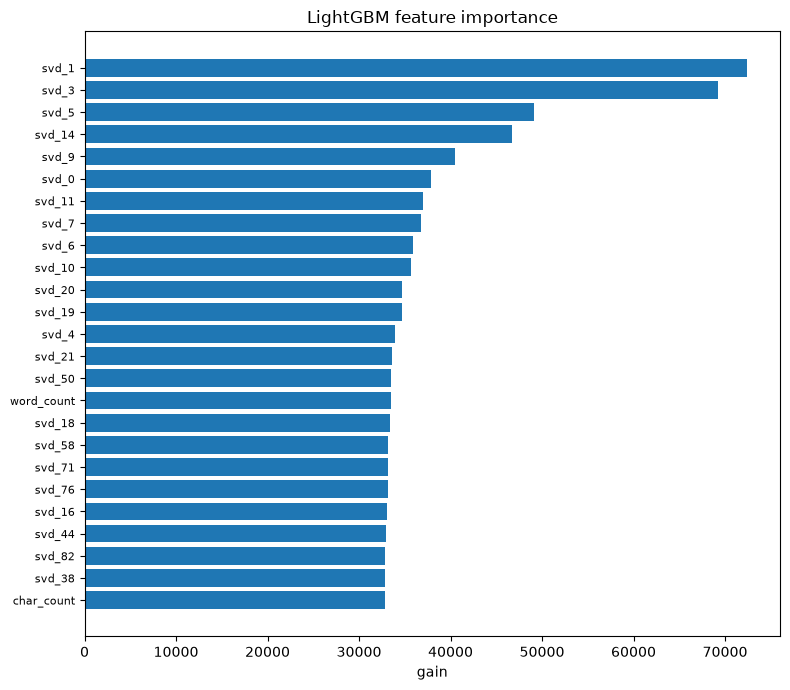

In [19]:
importance = pd.Series(booster.feature_importance('gain'), index=dense_train.columns)
top = importance.sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(range(len(top)), top.values[::-1])
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index[::-1], fontsize=8)
ax.set_xlabel('gain')
ax.set_title('LightGBM feature importance')
plt.tight_layout()
plt.show()

#### Insights

> Ridge sparse sudah mengalahkan hasil ModernBERT iterasi pertama dengan selisih besar, bukan karena model linear lebih kuat, melainkan karena iterasi pertama meregresikan dolar mentah. Angka ini adalah pengingat bahwa ruang target mengalahkan arsitektur.

> Komponen SVD mendominasi importance LightGBM dibanding fitur hasil regex, yang wajar karena hanya seperlima listing menyebut luas. Fitur regex tetap dipakai karena ia menambah sinyal pada baris yang justru paling mahal.

---

# Transformer Fine-Tuning <a name="6"></a>

---

Transformer adalah satu-satunya komponen yang bisa membaca urutan kata, dan urutan itulah yang membedakan `"needs a new roof"` dari `"new roof"`. Dua backbone dilatih dengan resep yang sama agar ensemble mendapat dua sumber kesalahan yang tidak berkorelasi penuh: DeBERTa-v3-large dengan disentangled attention, dan ModernBERT-large dengan tokenizer dan data pretraining yang berbeda.

## Target Scaling

Log harga distandardisasi memakai statistik fold training saja. Standardisasi tidak mengubah urutan prediksi tetapi membuat magnitudo gradien head sebanding dengan bobot backbone, sehingga learning rate tunggal bekerja untuk keduanya.

In [20]:
@dataclass
class TargetScaler:
    mean: float = 0.0
    std: float = 1.0

    def fit(self, values: np.ndarray) -> 'TargetScaler':
        self.mean = float(values.mean())
        self.std = float(values.std()) or 1.0
        return self

    def forward(self, values: np.ndarray) -> np.ndarray:
        return (values - self.mean) / self.std

    def inverse(self, values: np.ndarray) -> np.ndarray:
        return values * self.std + self.mean

## Dataset and Model

Tokenisasi dilakukan sekali per backbone untuk seluruh korpus, lalu batch disusun dengan padding dinamis. Head memakai mean pooling atas attention mask, bukan token CLS, karena sinyal harga tersebar di seluruh deskripsi dan bukan terkonsentrasi di awal kalimat.

In [21]:
class TextDataset(Dataset):
    def __init__(self, encodings, targets=None):
        self.input_ids = encodings['input_ids']
        self.attention_mask = encodings['attention_mask']
        self.targets = targets

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, i):
        item = {'input_ids': self.input_ids[i], 'attention_mask': self.attention_mask[i]}
        if self.targets is not None:
            item['target'] = float(self.targets[i])
        return item


def make_collate(pad_id):
    def collate(batch):
        width = max(len(b['input_ids']) for b in batch)
        ids = torch.full((len(batch), width), pad_id, dtype=torch.long)
        mask = torch.zeros((len(batch), width), dtype=torch.long)
        for row, item in enumerate(batch):
            n = len(item['input_ids'])
            ids[row, :n] = torch.tensor(item['input_ids'], dtype=torch.long)
            mask[row, :n] = torch.tensor(item['attention_mask'], dtype=torch.long)
        out = {'input_ids': ids, 'attention_mask': mask}
        if 'target' in batch[0]:
            out['target'] = torch.tensor([b['target'] for b in batch], dtype=torch.float)
        return out
    return collate

In [22]:
class PriceRegressor(nn.Module):
    def __init__(self, model_name: str):
        super().__init__()
        config = AutoConfig.from_pretrained(model_name)
        config.update({'hidden_dropout_prob': 0.0, 'attention_probs_dropout_prob': 0.0})
        self.backbone = AutoModel.from_pretrained(model_name, config=config).float()
        self.head = nn.Linear(config.hidden_size, 1)
        nn.init.normal_(self.head.weight, std=0.01)
        nn.init.zeros_(self.head.bias)

    def forward(self, input_ids, attention_mask):
        hidden = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-6)
        return self.head(pooled).squeeze(-1)

## Layer-Wise Learning Rate Decay

Lapisan bawah encoder menyimpan sintaksis umum yang tidak perlu banyak berubah, sedangkan lapisan atas harus beradaptasi ke domain properti. Learning rate dikalikan 0,9 per lapisan dari atas ke bawah, dan head mendapat learning rate sepuluh kali lipat karena ia dimulai acak. Letak blok transformer berbeda antar arsitektur, jadi `backbone_blocks` mencarinya alih-alih mengasumsikan `encoder.layer` seperti pada BERT.

In [23]:
def backbone_blocks(backbone: nn.Module) -> list:
    for path in (('encoder', 'layer'), ('encoder', 'layers'), ('layers',), ('transformer', 'layer')):
        node = backbone
        for attr in path:
            node = getattr(node, attr, None)
            if node is None:
                break
        if node is not None:
            return list(node)
    raise ValueError(f'tidak menemukan blok transformer pada {type(backbone).__name__}')


def build_optimizer(model: nn.Module, base_lr: float) -> torch.optim.Optimizer:
    no_decay = ('bias', 'LayerNorm.weight', 'layer_norm', 'norm.weight')
    layers = [model.backbone.embeddings] + backbone_blocks(model.backbone)
    groups = [{'params': model.head.parameters(), 'lr': CFG.head_lr, 'weight_decay': 0.0}]
    lr = base_lr
    for layer in reversed(layers):
        decay_params, plain_params = [], []
        for name, param in layer.named_parameters():
            (plain_params if any(k in name for k in no_decay) else decay_params).append(param)
        groups.append({'params': decay_params, 'lr': lr, 'weight_decay': CFG.weight_decay})
        groups.append({'params': plain_params, 'lr': lr, 'weight_decay': 0.0})
        lr *= CFG.llrd
    return torch.optim.AdamW(groups, lr=base_lr, eps=1e-6, betas=(0.9, 0.999))

## Training Loop

Loop ditulis manual agar evaluasi dapat dijalankan dua kali per epoch dan checkpoint terbaik dipilih berdasarkan MAE dolar, bukan loss di ruang standar. Loss `SmoothL1` dengan beta 0,25 berperilaku seperti L1 untuk residual di atas seperempat deviasi log, yaitu mayoritas kasus, tetapi tetap mulus di sekitar nol sehingga gradiennya tidak berosilasi.

In [24]:
@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    out = []
    for batch in loader:
        ids = batch['input_ids'].to(DEVICE, non_blocking=True)
        mask = batch['attention_mask'].to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
            out.append(model(ids, mask).float().cpu())
    return torch.cat(out).numpy()


def train_one_fold(model_name, batch_size, accum, base_lr,
                   encodings_train, encodings_test, train_idx, valid_idx, fold_id):
    seed_everything(CFG.seed + fold_id)
    tokenizer = TOKENIZERS[model_name]
    scaler = TargetScaler().fit(log_price[train_idx])

    collate = make_collate(tokenizer.pad_token_id)
    train_set = TextDataset({k: [v[i] for i in train_idx] for k, v in encodings_train.items()},
                            scaler.forward(log_price[train_idx]))
    valid_set = TextDataset({k: [v[i] for i in valid_idx] for k, v in encodings_train.items()})
    test_set = TextDataset(encodings_test)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True,
                              collate_fn=collate, num_workers=2, pin_memory=True)
    valid_loader = DataLoader(valid_set, batch_size=CFG.infer_batch_size, shuffle=False,
                              collate_fn=collate, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_set, batch_size=CFG.infer_batch_size, shuffle=False,
                             collate_fn=collate, num_workers=2, pin_memory=True)

    model = PriceRegressor(model_name).to(DEVICE)
    if CFG.gradient_checkpointing:
        model.backbone.gradient_checkpointing_enable()
    optimizer = build_optimizer(model, base_lr)
    steps_per_epoch = max(len(train_loader) // accum, 1)
    total_steps = max(int(steps_per_epoch * CFG.epochs), 1)
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, int(total_steps * CFG.warmup_ratio), total_steps)
    criterion = nn.SmoothL1Loss(beta=CFG.huber_beta)

    eval_every = max(total_steps // int(max(CFG.epochs * CFG.evals_per_epoch, 1)), 1)
    best_mae, best_state = float('inf'), None
    step, done = 0, False
    started = time.time()

    while not done:
        model.train()
        for micro, batch in enumerate(train_loader):
            ids = batch['input_ids'].to(DEVICE, non_blocking=True)
            mask = batch['attention_mask'].to(DEVICE, non_blocking=True)
            target = batch['target'].to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
                loss = criterion(model(ids, mask), target) / accum
            loss.backward()
            if (micro + 1) % accum:
                continue
            nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            if step % eval_every == 0 or step >= total_steps:
                valid_log = scaler.inverse(predict_logits(model, valid_loader))
                fold_mae = price_mae(valid_log, valid_idx)
                if fold_mae < best_mae:
                    best_mae = fold_mae
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                print(f'    step {step:>4}/{total_steps}  valid MAE {fold_mae:>10,.0f}'
                      f'  best {best_mae:>10,.0f}  {time.time() - started:>6.0f}s')
                model.train()
            if step >= total_steps:
                done = True
                break

    model.load_state_dict(best_state)
    valid_log = scaler.inverse(predict_logits(model, valid_loader))
    test_log = scaler.inverse(predict_logits(model, test_loader))
    peak = torch.cuda.max_memory_allocated() / 1024 ** 3 if DEVICE.type == 'cuda' else 0.0
    print(f'  fold {fold_id} done  MAE {best_mae:,.0f}  {(time.time() - started) / 60:.1f} min'
          f'  peak VRAM {peak:.1f} GiB')

    del model, optimizer, best_state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    return valid_log, test_log

## Running Every Backbone

Setiap backbone menjalani lima fold penuh. Prediksi test dirata-rata antar fold di ruang log, bukan di ruang dolar, agar rata-rata tetap konsisten dengan target yang dilatih.

Hasil setiap backbone langsung masuk ke `OOF_LOG` dan disimpan ke disk begitu selesai. Kalau waktu sewa GPU habis di tengah backbone kedua, sel blending tetap dapat dijalankan dengan apa pun yang sudah ada, dan submisi tetap valid dengan satu transformer saja.

In [25]:
TOKENIZERS = {}

for model_name, max_length, batch_size, accum, base_lr in CFG.backbones:
    tag = model_name.split('/')[-1].lower().replace('-', '_')
    print(f'\n=== {model_name}  len={max_length}  bs={batch_size}x{accum}  lr={base_lr} ===')
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    TOKENIZERS[model_name] = tokenizer
    enc_train = tokenizer(train['model_text'].tolist(), truncation=True, max_length=max_length)
    enc_test = tokenizer(test['model_text'].tolist(), truncation=True, max_length=max_length)
    lengths = np.array([len(x) for x in enc_train['input_ids']])
    print(f'token length p50={np.percentile(lengths, 50):.0f} '
          f'p95={np.percentile(lengths, 95):.0f} truncated={np.mean(lengths >= max_length):.1%}')

    oof = np.zeros(len(train))
    test_pred = np.zeros(len(test))
    for fold_id, (train_idx, valid_idx) in enumerate(SPLITS):
        valid_log, test_log = train_one_fold(
            model_name, batch_size, accum, base_lr,
            enc_train, enc_test, train_idx, valid_idx, fold_id)
        oof[valid_idx] = valid_log
        test_pred += test_log / CFG.n_folds

    OOF_LOG[tag] = oof
    TEST_LOG[tag] = test_pred
    SCOREBOARD.append(report(tag, oof))
    np.save(CFG.out_dir / f'oof_{tag}.npy', oof)
    np.save(CFG.out_dir / f'test_{tag}.npy', test_pred)


=== microsoft/deberta-v3-large  len=640  bs=8x2  lr=1e-05 ===
token length p50=173 p95=388 truncated=0.5%
    step  366/2196  valid MAE    356,008  best    356,008     109s
    step  732/2196  valid MAE    328,146  best    328,146     215s
    step 1098/2196  valid MAE    311,882  best    311,882     324s
    step 1464/2196  valid MAE    304,531  best    304,531     430s
    step 1830/2196  valid MAE    301,186  best    301,186     539s
    step 2196/2196  valid MAE    297,517  best    297,517     645s
  fold 0 done  MAE 297,517  11.7 min  peak VRAM 24.2 GiB
    step  366/2196  valid MAE    439,519  best    439,519     106s
    step  732/2196  valid MAE    310,844  best    310,844     214s
    step 1098/2196  valid MAE    287,368  best    287,368     320s
    step 1464/2196  valid MAE    280,394  best    280,394     427s
    step 1830/2196  valid MAE    275,888  best    275,888     532s
    step 2196/2196  valid MAE    270,450  best    270,450     639s
  fold 1 done  MAE 270,450  11.5

#### Insights

> Panjang token median hanya sekitar 185 dan persentil 95 sekitar 400, jadi padding dinamis membuat sebagian besar batch jauh lebih pendek daripada `max_length`. Jendela 640 memotong 0,55 persen listing, sedangkan 512 memotong 1,42 persen dan 384 memotong 5,76 persen. Yang terpotong selalu listing terpanjang, yaitu justru baris mewah yang menentukan MAE.

> Checkpoint dipilih dengan MAE dolar, bukan loss standar. Keduanya tidak selalu bergerak searah karena satu baris dengan harga puluhan juta dapat menggeser MAE tanpa menggeser loss log.

---

# Blending and Calibration <a name="7"></a>

---

Penggabungan dilakukan di ruang log, tempat semua model dilatih. Bobot dicari dengan non-negative least squares pada prediksi OOF, lalu hasilnya dikalibrasi. Kalibrasi bukan hiasan: EDA menunjukkan desil prediksi teratas hanya mencapai 0,84 kali harga sebenarnya, yang merupakan penyusutan khas regresi dan bukan derau acak.

## Correlation Between Models

Ensemble hanya membantu jika kesalahannya berbeda. Matriks korelasi residual memperlihatkan berapa banyak informasi baru yang dibawa setiap model.

In [26]:
scoreboard = pd.DataFrame(SCOREBOARD).sort_values('oof_mae')
print(scoreboard.to_string(index=False, float_format=lambda v: f'{v:,.0f}'))

residuals = pd.DataFrame({name: log_price - oof for name, oof in OOF_LOG.items()})
print('\nkorelasi residual di ruang log')
print(residuals.corr().to_string(float_format=lambda v: f'{v:.3f}'))

           model  oof_mae  median_ae  fold_std
deberta_v3_large  279,714    105,311    19,920
modernbert_large  340,567    128,769    20,368
      svr_sparse  348,752    134,818    21,769
            lgbm  349,027    127,621    26,406
    ridge_sparse  349,090    133,463    22,302

korelasi residual di ruang log
                  ridge_sparse  svr_sparse  lgbm  deberta_v3_large  modernbert_large
ridge_sparse             1.000       0.981 0.835             0.721             0.792
svr_sparse               0.981       1.000 0.835             0.718             0.788
lgbm                     0.835       0.835 1.000             0.741             0.829
deberta_v3_large         0.721       0.718 0.741             1.000             0.801
modernbert_large         0.792       0.788 0.829             0.801             1.000


## Weight Search

Bobot dicari dengan non-negative least squares pada log harga, yang memberi solusi tertutup, lalu dinormalkan. Karena metriknya MAE dan bukan MSE, hasil NNLS dipakai sebagai titik awal dan diperbaiki dengan pencarian koordinat langsung pada MAE dolar.

In [27]:
names = list(OOF_LOG)
oof_matrix = np.column_stack([OOF_LOG[n] for n in names])
test_matrix = np.column_stack([TEST_LOG[n] for n in names])

weights, _ = nnls(oof_matrix, log_price)
weights = weights / max(weights.sum(), 1e-9)
print('bobot NNLS :', {n: round(float(w), 3) for n, w in zip(names, weights)})
print(f'MAE NNLS   : {price_mae(oof_matrix @ weights):,.0f}')

for _ in range(60):
    improved = False
    for j in range(len(names)):
        for delta in (0.04, -0.04, 0.01, -0.01):
            trial = weights.copy()
            trial[j] = max(trial[j] + delta, 0.0)
            if trial.sum() <= 0:
                continue
            trial = trial / trial.sum()
            if price_mae(oof_matrix @ trial) < price_mae(oof_matrix @ weights) - 1.0:
                weights, improved = trial, True
    if not improved:
        break

BLEND_WEIGHTS = weights
blend_oof = oof_matrix @ BLEND_WEIGHTS
blend_test = test_matrix @ BLEND_WEIGHTS
print('bobot akhir:', {n: round(float(w), 3) for n, w in zip(names, BLEND_WEIGHTS)})
print(f'MAE blend  : {price_mae(blend_oof):,.0f}')

bobot NNLS : {'ridge_sparse': 0.213, 'svr_sparse': 0.0, 'lgbm': 0.0, 'deberta_v3_large': 0.787, 'modernbert_large': 0.0}
MAE NNLS   : 278,981
bobot akhir: {'ridge_sparse': 0.0, 'svr_sparse': 0.12, 'lgbm': 0.01, 'deberta_v3_large': 0.87, 'modernbert_large': 0.0}
MAE blend  : 277,550


## Calibration

Lima kandidat kalibrasi diuji dengan fold yang sama. Setiap kandidat ditulis sebagai fungsi yang dipasang pada indeks tertentu dan mengembalikan transformasi, sehingga semuanya dapat dinilai secara cross-fit dengan perlakuan identik.

In [28]:
def fit_identity(idx):
    return lambda values: values


def fit_shift(idx):
    grid = np.linspace(-0.20, 0.20, 81)
    best = min(grid, key=lambda d: price_mae(blend_oof[idx] + d, idx))
    return lambda values: values + best


def fit_stretch(idx):
    centre = float(blend_oof[idx].mean())
    grid = np.linspace(0.85, 1.55, 71)
    best = min(grid, key=lambda s: price_mae(centre + s * (blend_oof[idx] - centre), idx))
    return lambda values: centre + best * (values - centre)


def fit_isotonic(idx):
    iso = IsotonicRegression(out_of_bounds='clip').fit(blend_oof[idx], log_price[idx])
    return iso.predict


def fit_rank_match(idx):
    reference = np.sort(blend_oof[idx])
    targets = np.sort(log_price[idx])
    grid = np.linspace(0.0, 1.0, len(targets))
    def apply(values):
        quantile = np.searchsorted(reference, values) / max(len(reference), 1)
        return np.interp(np.clip(quantile, 0.0, 1.0), grid, targets)
    return apply


CALIBRATIONS = {
    'none': fit_identity,
    'shift': fit_shift,
    'stretch': fit_stretch,
    'isotonic': fit_isotonic,
    'rank matching': fit_rank_match,
}

Setiap kandidat dipasang pada bagian training fold lalu diterapkan pada bagian validasi, sama seperti model. Tanpa itu, kalibrasi dengan banyak parameter seperti rank matching akan selalu menang karena dinilai pada data yang dipakai memasangnya. Transformasi untuk test dipasang sekali pada seluruh OOF setelah pemenangnya dipilih.

In [29]:
calibration_scores = {}
for label, fitter in CALIBRATIONS.items():
    crossfit = np.zeros(len(train))
    for train_idx, valid_idx in SPLITS:
        crossfit[valid_idx] = fitter(train_idx)(blend_oof[valid_idx])
    calibration_scores[label] = (price_mae(crossfit), crossfit)
    print(f'{label:22s} cross-fitted MAE {calibration_scores[label][0]:>10,.0f}')

BEST_CALIBRATION = min(calibration_scores, key=lambda k: calibration_scores[k][0])
final_oof = calibration_scores[BEST_CALIBRATION][1]
final_test = CALIBRATIONS[BEST_CALIBRATION](np.arange(len(train)))(blend_test)
print(f'\nterpilih: {BEST_CALIBRATION}  ({calibration_scores[BEST_CALIBRATION][0]:,.0f})')

none                   cross-fitted MAE    277,550
shift                  cross-fitted MAE    277,346
stretch                cross-fitted MAE    277,185
isotonic               cross-fitted MAE    278,689
rank matching          cross-fitted MAE    302,427

terpilih: stretch  (277,185)


Satu langkah pemolesan ditambahkan di atas pemenangnya: faktor perentang tunggal yang dicari pada keluaran kalibrasi yang sudah cross-fit. Mencarinya langsung di atas isotonic tidak akan bekerja, karena isotonic memetakan data yang dipakai memasangnya secara nyaris sempurna dan faktor optimalnya selalu keluar 1,00. Pemolesan hanya dipakai kalau ia benar-benar menang.

In [30]:
polish_oof = np.zeros(len(train))
factors = []
for train_idx, valid_idx in SPLITS:
    centre = float(final_oof[train_idx].mean())
    grid = np.linspace(0.85, 1.55, 71)
    best = min(grid, key=lambda s: price_mae(centre + s * (final_oof[train_idx] - centre), train_idx))
    polish_oof[valid_idx] = centre + best * (final_oof[valid_idx] - centre)
    factors.append((centre, best))

print(f'tanpa pemolesan {price_mae(final_oof):>10,.0f}')
print(f'dengan pemolesan {price_mae(polish_oof):>9,.0f}   faktor {[round(f, 2) for _, f in factors]}')
if price_mae(polish_oof) < price_mae(final_oof):
    centre = float(np.mean([c for c, _ in factors]))
    factor = float(np.mean([f for _, f in factors]))
    final_oof = polish_oof
    final_test = centre + factor * (final_test - centre)
    BEST_CALIBRATION = f'{BEST_CALIBRATION} + stretch x{factor:.2f}'
    print(f'pemolesan dipakai, kalibrasi akhir: {BEST_CALIBRATION}')
else:
    print('pemolesan tidak membantu, dilewati')

tanpa pemolesan    277,185
dengan pemolesan   277,899   faktor [np.float64(0.99), np.float64(1.0), np.float64(0.99), np.float64(0.99), np.float64(1.01)]
pemolesan tidak membantu, dilewati


           n   median_pred   median_true  pred_over_true
decile                                                  
0       1464   121,309.906   115,662.500           1.049
1       1464   234,075.984   230,000.000           1.018
2       1464   316,596.934   318,082.500           0.995
3       1464   390,041.466   389,000.000           1.003
4       1464   458,747.159   460,000.000           0.997
5       1464   532,407.029   548,944.000           0.970
6       1464   623,912.686   625,000.000           0.998
7       1464   753,855.409   750,000.000           1.005
8       1464   996,482.202   979,000.000           1.018
9       1464 1,943,142.259 2,091,500.000           0.929


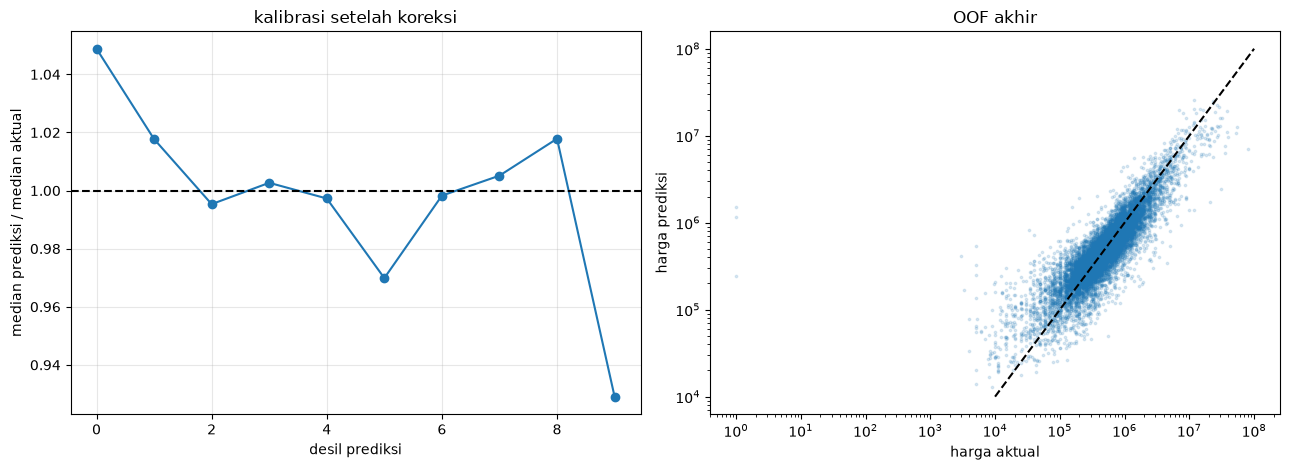

In [31]:
deciles = pd.qcut(final_oof, 10, labels=False)
check = pd.DataFrame({'decile': deciles, 'pred': np.exp(final_oof), 'true': y_price}).groupby('decile').agg(
    n=('true', 'size'), median_pred=('pred', 'median'), median_true=('true', 'median'))
check['pred_over_true'] = check['median_pred'] / check['median_true']
print(check.to_string(float_format=lambda v: f'{v:,.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(check.index, check['pred_over_true'], marker='o')
axes[0].axhline(1.0, color='k', ls='--')
axes[0].set_xlabel('desil prediksi')
axes[0].set_ylabel('median prediksi / median aktual')
axes[0].set_title('kalibrasi setelah koreksi')
axes[0].grid(alpha=0.3)
axes[1].scatter(y_price, np.exp(final_oof), s=3, alpha=0.15)
axes[1].plot([1e4, 1e8], [1e4, 1e8], 'k--')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('harga aktual')
axes[1].set_ylabel('harga prediksi')
axes[1].set_title('OOF akhir')
plt.tight_layout()
plt.show()

#### Insights

> Kalibrasi hanya dianggap berhasil jika rasio prediksi terhadap aktual mendekati satu di seluruh desil, terutama desil teratas. Jika desil teratas masih di bawah 0,9, model tetap kehilangan uang pada baris yang paling mahal dan kalibrasi belum cukup agresif.

> Perhatikan bahwa isotonic dipasang out-of-fold untuk pelaporan. Memasangnya pada OOF penuh lalu melaporkan skor pada OOF yang sama akan memberi angka yang lebih baik dan tidak benar.

> Rank matching sengaja disertakan sebagai kandidat yang diperkirakan kalah. Dinilai secara cross-fit pada baseline LinearSVR, ia memperbaiki rasio desil teratas dari 0,62 menjadi 0,80 tetapi menaikkan MAE dari 348.449 menjadi 389.219. MAE meminta median bersyarat, dan median dari prediksi yang tidak pasti memang seharusnya mendekati pusat. Memaksa distribusi prediksi menyerupai distribusi target menukar bias dengan varians, dan varians itulah yang ditagih MAE.

> Kalau dinilai dalam sampel, rank matching justru menang, karena ia punya satu parameter per baris. Itulah alasan setiap kandidat di sini dipasang out-of-fold.

---

# Submission <a name="8"></a>

---

Langkah terakhir menerapkan dua koreksi yang tidak berasal dari model, lalu menulis file submisi dengan format persis seperti `sample_submission.csv`. Koreksi kembar mengambil harga train untuk baris test yang teksnya praktis identik, dan batas bawah mencegah prediksi turun ke wilayah harga yang tidak pernah muncul di data.

In [32]:
final_price = np.exp(final_test)

twin_mask = TWIN_SIM >= CFG.twin_threshold
print(f'baris test memakai harga kembarannya: {int(twin_mask.sum())}')
if twin_mask.any():
    before = final_price[twin_mask].copy()
    final_price[twin_mask] = TWIN_PRICE[twin_mask]
    shift = np.abs(final_price[twin_mask] - before)
    print(f'pergeseran median pada baris tersebut: {np.median(shift):,.0f}')

lower, upper = np.quantile(y_price, 0.0005), np.quantile(y_price, 0.9999)
clipped = int(((final_price < lower) | (final_price > upper)).sum())
final_price = np.clip(final_price, lower, upper)
print(f'batas prediksi [{lower:,.0f}, {upper:,.0f}], baris terpotong: {clipped}')

baris test memakai harga kembarannya: 27
pergeseran median pada baris tersebut: 26,736
batas prediksi [4,999, 53,499,113], baris terpotong: 0


In [33]:
submission = pd.DataFrame({'id': test['id'], 'listPrice': final_price})
assert submission['id'].tolist() == sample_submission['id'].tolist()
assert submission['listPrice'].notna().all()
assert (submission['listPrice'] > 0).all()

path = CFG.out_dir / 'submission.csv'
submission.to_csv(path, index=False)
print(f'ditulis ke {path}')
print(submission.head().to_string(index=False))

print('\nsebaran prediksi vs train')
comparison = pd.DataFrame({
    'quantile': [0.05, 0.25, 0.5, 0.75, 0.95, 0.99],
    'train': [np.quantile(y_price, q) for q in [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]],
    'submission': [np.quantile(final_price, q) for q in [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]],
})
print(comparison.to_string(index=False, float_format=lambda v: f'{v:,.0f}'))

ditulis ke outputs/v2/submission.csv
       id    listPrice
RE_015637 3.158456e+05
RE_005176 4.239715e+05
RE_013544 7.281297e+05
RE_016667 5.484938e+05
RE_011479 1.338150e+06

sebaran prediksi vs train
 quantile     train  submission
        0    94,900     127,526
        0   299,900     314,644
        0   499,900     495,448
        1   799,900     807,055
        1 2,300,000   2,600,552
        1 6,561,000   8,225,008


## Run Manifest

Manifest mencatat konfigurasi, skor tiap model, bobot ensemble, dan hash file input, agar run ini dapat dibandingkan dengan run berikutnya tanpa menebak apa yang berubah.

In [34]:
manifest = {
    'profile': PROFILE,
    'config': {k: str(v) for k, v in asdict(CFG).items()},
    'scoreboard': pd.DataFrame(SCOREBOARD).to_dict('records'),
    'blend_weights': {n: float(w) for n, w in zip(names, BLEND_WEIGHTS)},
    'blend_oof_mae': price_mae(blend_oof),
    'calibration': BEST_CALIBRATION,
    'calibrated_oof_mae': price_mae(final_oof),
    'twin_overrides': int(twin_mask.sum()),
    'submission_rows': len(submission),
}
(CFG.out_dir / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
np.save(CFG.out_dir / 'blend_oof.npy', final_oof)
print(json.dumps(manifest, indent=2))

{
  "profile": "full",
  "config": {
    "data_dir": "data",
    "out_dir": "outputs/v2",
    "seed": "42",
    "n_folds": "5",
    "price_floor": "10000.0",
    "duplicate_threshold": "0.85",
    "twin_threshold": "0.97",
    "backbones": "(('microsoft/deberta-v3-large', 640, 8, 2, 1e-05), ('answerdotai/ModernBERT-large', 768, 8, 2, 1.5e-05))",
    "epochs": "3.0",
    "head_lr": "0.0001",
    "llrd": "0.9",
    "weight_decay": "0.01",
    "warmup_ratio": "0.06",
    "huber_beta": "0.25",
    "evals_per_epoch": "2",
    "max_grad_norm": "1.0",
    "gradient_checkpointing": "False",
    "infer_batch_size": "32"
  },
  "scoreboard": [
    {
      "model": "ridge_sparse",
      "oof_mae": 349089.8743140871,
      "median_ae": 133462.60592759092,
      "fold_std": 22302.283957455074
    },
    {
      "model": "svr_sparse",
      "oof_mae": 348752.3012075649,
      "median_ae": 134817.55936973233,
      "fold_std": 21769.136557079884
    },
    {
      "model": "lgbm",
      "oof_mae": 34

#### Insights

> Kuantil prediksi harus mendekati kuantil train pada bagian tengah, tetapi boleh sedikit lebih tinggi di ujung atas. EDA menunjukkan test memang condong lebih mahal, dengan rasio 1,30 pada kuantil 0,99.

> Jika kuantil 0,95 submisi jauh di bawah kuantil 0,95 train, model masih menyusut dan kalibrasi perlu diperkuat sebelum submit.